<img src="logo.png" alt="Vegeta" width="240">

# Svarog-2kW — the welding laser at two kilowatts

Notebook 48's 1 kW device doubled, two ways, on the same Hyperion chain: **(A) two 1 kW modules beam-combined** through
a (2+1)×1 signal combiner into a 100 µm process fibre — the industrial route, which costs beam quality (the étendues add:
BPP 3 → 6 mm·mrad, M² 9 → 18) and a 200 µm spot; **(B) one power stage pumped harder** with 400 W modules in the same
(6+1)×1 combiner and a longer 30/250 fibre — keeps the 50 µm fibre and the 100 µm spot but puts 2 kW through one fibre
(SRS margin, 220 W of heat on one spool). Then the welds at 2 kW for both spots, and the guard re-screened at the doubled
irradiance — the steel barriers' real check. The design module is `designs/svarog_industrial.py`; the record goes to
`designs/data/reports/51_svarog_2kw.json`.

In [1]:
DEBUG = False
from vegeta import mock
DEBUG = mock.setup(DEBUG)

In [2]:
import json, math, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, "designs")
from vegeta import hyperion as hy
from vegeta.hyperion import welding as wd
import svarog_industrial as si, svarog_industrial_drawings as sid, svarog_fiber_drawings as sfd

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 240)
OUT = Path("output/51_svarog_2kw"); OUT.mkdir(parents=True, exist_ok=True)
DATA = Path("designs/data")
from vegeta import yanus
GATE = yanus.enter("51_svarog_2kw", debug=DEBUG)      # needs vegeta.hyperion; takes 48's report (optional); gives the report
R48_PATH = DATA / "reports" / "48_svarog_weld.json"
R48 = json.loads(R48_PATH.read_text()) if R48_PATH.exists() else None
SEED = R48["meta"]["seed_W"] if R48 else si.SEED_DEFAULT
MODULE_1KW = R48["meta"]["delivered_W"] if R48 else 933.0
print(f"from notebook 48: seed {SEED:.1f} W, one module delivers {MODULE_1KW:.0f} W to the head" if R48 else "WARNING: 48's report missing — defaults used")

from notebook 48: seed 58.9 W, one module delivers 933 W to the head


## 1. Route A — two 1 kW modules combined

Two of notebook 48's modules into a (2+1)×1 signal combiner: the output fibre must hold the sum of the étendues, so a
100/125 µm, NA 0.12 process fibre (BPP 6 mm·mrad); 97 % through the combiner. The same 100/200 head then makes a 200 µm
spot — a quarter of the irradiance per watt, half the keyhole margin, but each module runs exactly as designed.

In [3]:
COMB = si.SignalCombiner(n_inputs=2, r_in=si.FIBRE_POWER.core_radius, na_in=si.FIBRE_POWER.NA, r_out=si.DELIVERY_100.core_radius, na_out=si.DELIVERY_100.NA)
P_A = COMB.combined_W(MODULE_1KW / 10 ** (-0.3 / 10))     # the modules' outputs before their own process-fibre loss
P_A_HEAD = P_A * 10 ** (-0.3 / 10)
HN_A = si.head_numbers(P_A_HEAD, si.DELIVERY_100)
print(f"combiner fits the étendue: {COMB.fits}; {COMB.n_inputs} × {MODULE_1KW / 10 ** (-0.3 / 10):.0f} W → {P_A:.0f} W combined, {P_A_HEAD:.0f} W at the head")
display(pd.Series({"BPP [mm·mrad]": HN_A["bpp_mm_mrad"], "M²": HN_A["m2"], "spot radius [µm]": HN_A["spot_radius"] * 1e6, "cone half-angle [mrad]": HN_A["cone_half_angle"] * 1e3,
                   "Rayleigh length [mm]": HN_A["rayleigh_length"] * 1e3, "mean irradiance [MW/cm²]": HN_A["mean_irradiance_W_per_cm2"] / 1e6,
                   "SRS threshold, 100 µm fibre [kW]": HN_A["srs_delivery"]["P_threshold_W"] / 1e3}, name="route A at the head").round(3))

combiner fits the étendue: True; 2 × 1000 W → 1940 W combined, 1811 W at the head


BPP [mm·mrad]                         6.000
M²                                   17.616
spot radius [µm]                    100.000
cone half-angle [mrad]               60.000
Rayleigh length [mm]                  1.667
mean irradiance [MW/cm²]              5.763
SRS threshold, 100 µm fibre [kW]     27.813
Name: route A at the head, dtype: float64

## 2. Route B — one stage pumped harder

The same 30/250 fibre, 400 W modules on the same six ports (the étendue is the pigtail's, not the power's: it still fits),
the length chosen by the 3 % rule at the modules' maximum and the pump set for 2 kW out. What changes: 220 W of heat on
one spool, 76 W/m at the pump end, and 2 kW through a 30/250 core — the SRS margin shrinks to a few times.

route B: 10 m, pump 2230 W of 2280 W → 2000 W out (15.3 dB), heat 216 W, peak 77 W/m, SRS margin 3.5×  [13 s]


core rise, water-cooled spool [K]      82.85
into the stripper [W]                 116.33
delivered to the head [W]            1866.51
absorbed per lens [W]                   3.73
lens centre rise [K]                  111.40
Name: route B budget, dtype: float64

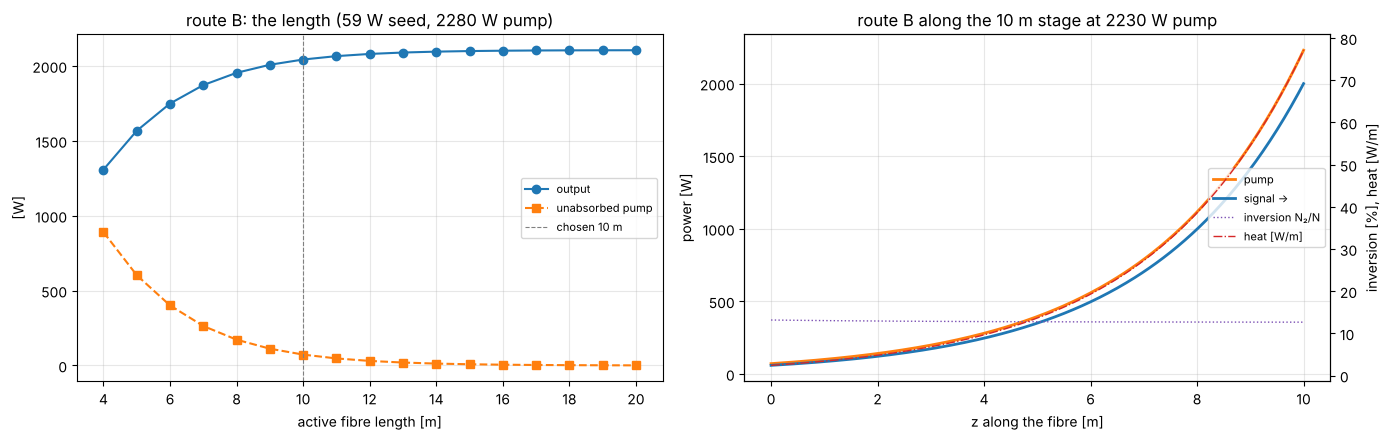

In [4]:
t0 = time.time()
LC_B = si.power_stage_length_choice(SEED, si.PUMP_400.launched_max, n=si.N_SWEEP)
LEN_B = LC_B["chosen_length"]
PUMP_B = si.pump_for_target_with(LEN_B, SEED, 2000.0, si.PUMP_400, n=si.N_SWEEP)
SOL_B = si.power_stage(LEN_B).solve(SEED, PUMP_B, n=si.N_FINE)
BUD_B = si.thermal_budget(SOL_B, LEN_B)
LIM_B = si.sf.limits(si.FIBRE_POWER, LEN_B, SOL_B, SOL_B.output_W)
print(f"route B: {LEN_B:g} m, pump {PUMP_B:.0f} W of {si.PUMP_400.launched_max:.0f} W → {SOL_B.output_W:.0f} W out ({SOL_B.gain_db:.1f} dB), heat {SOL_B.heat_W:.0f} W, peak {SOL_B.peak_heat_per_m:.0f} W/m, "
      f"SRS margin {LIM_B['srs_margin']:.1f}×  [{time.time() - t0:.0f} s]")
display(pd.Series({"core rise, water-cooled spool [K]": BUD_B["core_dT_per_cooling"]["water-cooled spool (h 2000)"], "into the stripper [W]": BUD_B["stripper_W"],
                   "delivered to the head [W]": BUD_B["delivered_W"], "absorbed per lens [W]": BUD_B["lens_absorbed_W_each"], "lens centre rise [K]": BUD_B["lens_centre_dT"]}, name="route B budget").round(2))
HN_B = si.head_numbers(BUD_B["delivered_W"])
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
sfd.length_view(LC_B, ax=axs[0], title=f"route B: the length ({SEED:.0f} W seed, {si.PUMP_400.launched_max:.0f} W pump)")
sfd.evolution_view(SOL_B, ax=axs[1], title=f"route B along the {LEN_B:g} m stage at {PUMP_B:.0f} W pump")
plt.tight_layout(); plt.savefig(OUT / "route_b.png", dpi=110); plt.show()

## 3. The welds at 2 kW — the two spots side by side

Route A's 200 µm spot and route B's 100 µm spot at ~1.9 kW each: the keyhole margins, the penetration against speed,
the process windows. The energy balance scales the depth with power over width: the 100 µm spot welds deeper and faster;
the 200 µm spot is the forgiving one (wider gap tolerance, a 1.7 mm depth of focus).

A: 200 µm spot — keyhole thresholds: {'mild steel': '75 W', 'aluminium': '1023 W'}
B: 100 µm spot — keyhole thresholds: {'mild steel': '37 W', 'aluminium': '512 W'}


0.3 m/min  0.5 m/min  0.75 m/min  1 m/min  1.5 m/min  2 m/min  3 m/min  4 m/min  6 m/min  8 m/min  10 m/min
A: 200 µm spot mild steel       5.92       4.45        3.52     2.98       2.34     1.96     1.52     1.26     0.96     0.79      0.68
               aluminium        5.14       3.94        3.18     2.73       2.19     1.88     1.50     1.28     1.01     0.86      0.75
B: 100 µm spot mild steel       8.91       6.75        5.39     4.58       3.63     3.07     2.41     2.02     1.56     1.30      1.12
               aluminium        7.58       5.82        4.72     4.06       3.28     2.81     2.26     1.93     1.55     1.32      1.16

thickness [mm]  v full [m/min]  v margin [m/min]  feasible
A: 200 µm spot mild steel 0             1.0            5.67              4.31      True
                          1             2.0            1.93              1.43      True
                          2             3.0            0.99              0.72      True
                          3             4.0            0.60              0.44      True
                          4             6.0            0.29              0.21      True
               aluminium  0             1.0            6.14              4.46      True
                          1             2.0            1.78              1.27      True
                          2             3.0            0.84              0.59      True
                          3             4.0            0.48              0.34      True
B: 100 µm spot mild steel 0             1.0           11.86              9.03      True
                          1             2.0            4.06              3.02      True
                          2             3.0            2.08              1.52      True
                          3             4.0            1.27              0.92      True
                          4             6.0            0.62              0.44      True
               aluminium  0             1.0           12.95              9.42      True
                          1             2.0            3.76              2.69      True
                          2             3.0            1.77              1.26      True
                          3             4.0            1.03              0.73      True

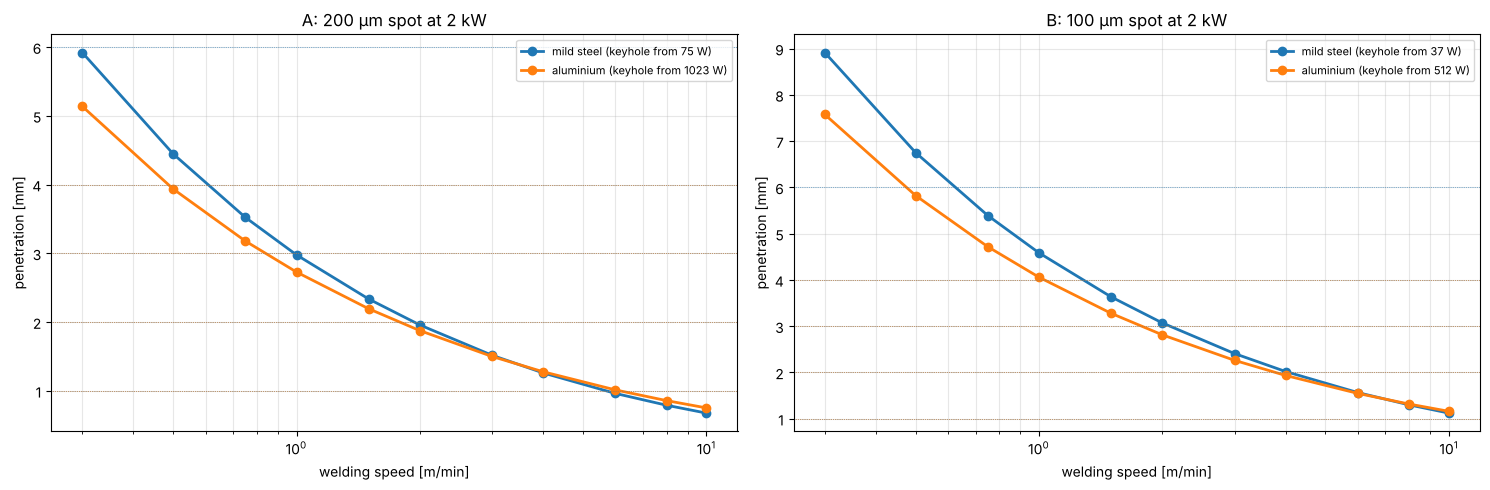

In [5]:
WELD = {"A: 200 µm spot": si.welds(P_A_HEAD, si.DELIVERY_100), "B: 100 µm spot": si.welds(BUD_B["delivered_W"])}
for route, w in WELD.items():
    print(route, "— keyhole thresholds:", {m: f"{d['keyhole']['P_threshold_W']:.0f} W" for m, d in w.items()})
PEN = pd.concat({route: pd.DataFrame({m: dict(zip([f"{v * 60:g} m/min" for v in si.SPEEDS], (d["curve"]["depth"] * 1e3).round(2))) for m, d in w.items()}).T for route, w in WELD.items()})
display(PEN)
WIN = pd.concat({(route, m): pd.DataFrame(d["window"]).assign(**{"thickness [mm]": lambda x: x["thickness"] * 1e3, "v full [m/min]": lambda x: x["v_full_penetration"] * 60,
                                                                  "v margin [m/min]": lambda x: x["v_with_margin"] * 60})[["thickness [mm]", "v full [m/min]", "v margin [m/min]", "feasible"]]
                 for route, w in WELD.items() for m, d in w.items()}); display(WIN.round(2))
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for ax, (route, w) in zip(axs, WELD.items()):
    sid.penetration_view(w, {n: [t * 1e3 for t in m["thicknesses"]] for n, m in si.WELD_MATERIALS.items()}, ax=ax); ax.set_title(f"{route} at 2 kW")
plt.tight_layout(); plt.savefig(OUT / "welds_2kw.png", dpi=110); plt.show()

## 4. The guard at 2 kW

The collimated beam of route A's head: 2 kW in 22 mm at 20 m (the 100 µm fibre's larger divergence spreads it a little),
128 W/cm² — against 103 W/cm² at 1 kW. The same screening and the same rule: the transient only where the steady solve
melts. The question is the steel: 1.5 mm steel ran at 1220 K under the kilowatt.

33 pairs, 5 simulated in 48 s


,holds [s],steady T_max [K],T1,T2,T3,decided by
barrier,,,,,,
black polycarbonate 5 mm,11.4,15251.2,True,False,False,simulation: ablated through at the centre
black polycarbonate 10 mm,22.7,11181.1,True,False,False,simulation: ablated through at the centre
clear polycarbonate 5 mm,0.0,NaN,False,False,False,fails: transparent
clear polycarbonate 10 mm,0.0,NaN,False,False,False,fails: transparent
laser-safety polycarbonate 5 mm,11.8,14858.8,True,False,False,simulation: ablated through at the centre
laser-safety polycarbonate 10 mm,23.4,10845.5,True,False,False,simulation: ablated through at the centre
fired clay brick 65 mm,inf,13811.5,True,True,True,simulation: steady
aluminium 1.5 mm,inf,NaN,True,True,True,survives: steady bound
aluminium 3 mm,inf,NaN,True,True,True,survives: steady bound


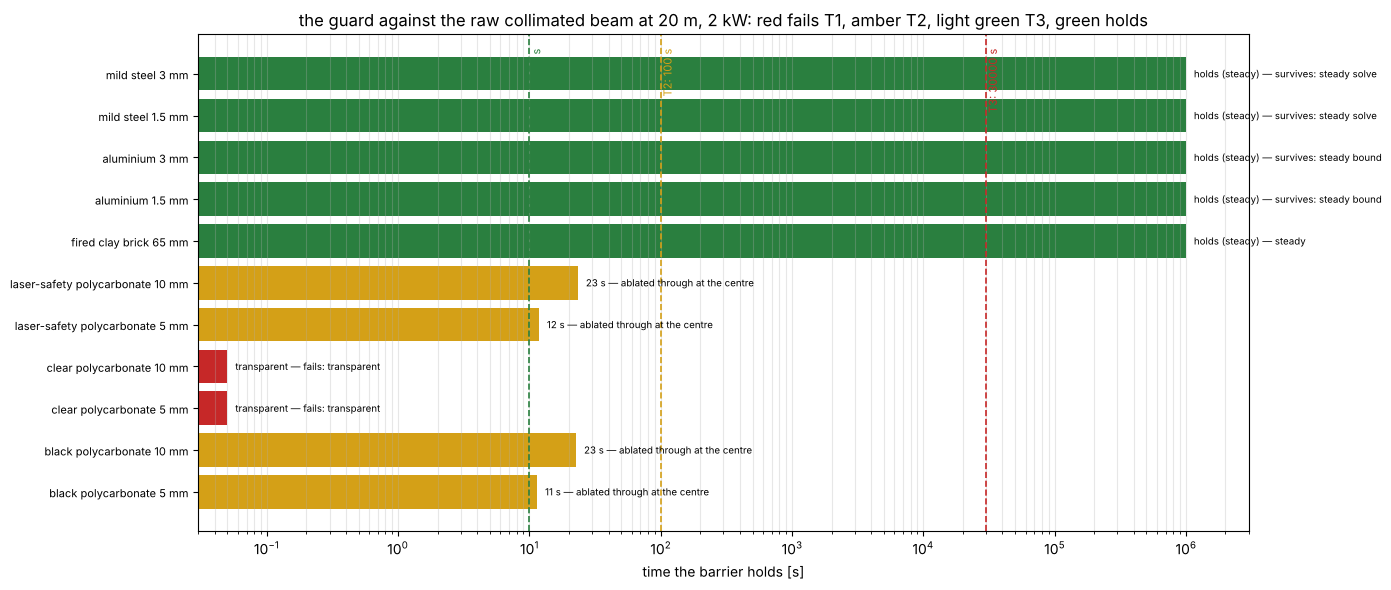

In [6]:
t0 = time.time()
G = si.guard_study(P_A_HEAD, delivery=si.DELIVERY_100)
print(f"{len(G['rows'])} pairs, {sum(r['simulated'] for r in G['rows'])} simulated in {time.time() - t0:.0f} s")
VER = pd.DataFrame([{"barrier": r["barrier"], "holds [s]": r["holds_s"], "steady T_max [K]": r["steady_T_max"], "T1": r["T1"], "T2": r["T2"], "T3": r["T3"], "decided by": r["source"]}
                    for r in G["rows"] if r["beam"] == "raw collimated beam"]).set_index("barrier")
display(VER.round(1))
fig, ax = plt.subplots(figsize=(14, 6)); sid.guard_timeline(G["rows"], si.EXPOSURE, ax=ax); ax.set_title(ax.get_title().replace("at 20 m", "at 20 m, 2 kW"))
plt.tight_layout(); plt.savefig(OUT / "guard_2kw.png", dpi=110); plt.show()

## 5. The record

In [7]:
def _j(o):
    if hasattr(o, "tolist"):
        return o.tolist()
    if hasattr(o, "to_dict"):
        return o.to_dict()
    if isinstance(o, float) and not math.isfinite(o):
        return None if math.isnan(o) else ("inf" if o > 0 else "-inf")
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return str(o)

REPORT = {"meta": {"notebook": "51_svarog_2kw", "seed_W": SEED, "module_1kW_W": MODULE_1KW, "debug": DEBUG, "source_report": str(R48_PATH) if R48 else None},
          "route_A": {"combiner": vars(COMB), "combined_W": P_A, "at_head_W": P_A_HEAD, "head": HN_A},
          "route_B": {"length": LEN_B, "pump_W": PUMP_B, **SOL_B.to_dict(), "budget": BUD_B, "srs_margin": LIM_B["srs_margin"], "head": HN_B},
          "welds": {route: {m: {"keyhole": d["keyhole"], "window": d["window"]} for m, d in w.items()} for route, w in WELD.items()},
          "guard": {"power_W": P_A_HEAD, "verdicts": [{k: v for k, v in r.items()} for r in G["rows"]]}}
(DATA / "reports").mkdir(parents=True, exist_ok=True)
(DATA / "reports" / "51_svarog_2kw.json").write_text(json.dumps(REPORT, indent=1, default=_j))
print("written", DATA / "reports" / "51_svarog_2kw.json")

written designs/data/reports/51_svarog_2kw.json


In [8]:
STAMPS = GATE.leave()

## 6. Reading it

- **Two kilowatts are either two modules or one hot fibre.** Route A keeps every module at its 1 kW design and pays in
  beam quality (M² 18, a 200 µm spot); route B keeps the 100 µm spot and pays with 220 W of heat on one spool and an SRS
  margin of a few times — fine for CW, the wall for pulses.
- **The welds follow power over width**: the 100 µm spot at 2 kW roughly doubles the 1 kW penetration; the 200 µm spot
  lands between the two and is the easier process to run.
- **The guard**: the plastics fail faster, the metals' steady states rise — the table above says whether 1.5 mm steel
  still holds at 128 W/cm² or the enclosure moves to 3 mm (MVP M.2 reads this notebook, not 49, for a 2 kW cell).